# Market Research for Various Product Ideas

In this notebook, we run market research simulations for which we have (or believe to have :-) the correct answers. This is mean to allow us both to evaluate the quality of the technology and to direct our efforts to improve it.

In [1]:
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, '..')

import tinytroupe
from tinytroupe.agent import TinyPerson
from tinytroupe.environment import TinyWorld
from tinytroupe.factory import TinyPersonFactory
from tinytroupe.validation import TinyPersonValidator
from tinytroupe import control

from tinytroupe.extraction import ResultsExtractor
from tinytroupe.profiling import Profiler


!!!!
DISCLAIMER: TinyTroupe relies on Artificial Intelligence (AI) models to generate content. 
The AI models are not perfect and may produce inappropriate or inacurate results. 
For any serious or consequential use, please review the generated content before using it.
!!!!

Looking for default config on: C:\Users\pdasilva\repos\TinyTroupe\examples\..\tinytroupe\utils\..\config.ini
Found custom config on: C:\Users\pdasilva\repos\TinyTroupe\examples\config.ini
TinyTroupe version: 0.5.1
Current date and time (local): 2025-07-26 15:02:30
Current date and time (UTC):   2025-07-26 18:02:30

Current TinyTroupe configuration 
[OpenAI]
api_type = openai
azure_api_version = 2024-08-01-preview
model = gpt-4.1-mini
reasoning_model = o3-mini
embedding_model = text-embedding-3-small
max_tokens = 32000
temperature = 1.5
freq_penalty = 0.1
presence_penalty = 0.1
timeout = 480
max_attempts = 5
waiting_time = 0
exponential_backoff_factor = 5
reasoning_effort = high
cache_api_calls = False
cache_file_n

First of all, we'll use a cached simulation, to avoid having to recompute expensive steps unless really necessary. We accomplish this via the `control.begin()` function. The file it takes as an argument is the cache file that will be created and then updated as needed.

**Tip:** the ".cache." naming convention is used to indicate that the file is a cache file and will not be committed to the repository.

In [2]:
control.begin("travel_product_market_research.cache.json")

## Prepare the survey and auxiliary elements

Main target nationality and population size.

In [3]:
target_nationality = "American"
population_size = 50

total_population_size = 70

Descriptions and standard questions for the survey.

In [4]:
nationality="American"

general_context =\
            f"""
            We are performing some market research, and in that examining the whole of the {nationality} population. 
            """

sampling_space_description =\
    f"""
    A uniform random representative sample of people from the {nationality} population. 
    Make sure you consider very detailed, fine-grained, characteristics of the individuals in the population.
    Please consider as many different population segments as possible, while always keeping proportions correct.
    For example, instead of sampling 10 people from segment A and 5 from segment B, you can instead
    sample 2 from A, 1 from B, and 7 others from other segments, provided the proportions are maintained correct.
    Besides anything you know about this population, also consider the following information 
    to sample proportionally to the presence of such groups and characteristics in the population.
    
              
    {json.dumps(json.loads(open("./information/populations/usa.json").read()), indent=4)}
    """

print(sampling_space_description)
#- from rich to poor.             
#              - from the very energetic to the very calm;
#              - from the happy and joyful to the sad and depressed;
#              - from the most introverted to the most extroverted;
#              - from the most adventurous to the most conservative;
#              - from the most artistic to the most scientific;
#              - from the most athletic to the most sedentary;
#              - from the most social to the most solitary;
#              - from the kind to the evil.
#    

#Experiment: Travel Preferences by Marital Status
#	•	Ground Truth:
#	•	Singles prefer adventure trips, with 62% citing nature or extreme sports as their ideal vacation (Expedia, 2023). Source
#	•	Families prioritize child-friendly destinations, with 73% choosing theme parks or resorts (Expedia, 2023). Source
#	•	Couples favor luxury/romantic getaways, with 81% preferring beachfront or spa destinations (Expedia, 2023). Source
#	•	Prediction Task: Predict travel preferences based on marital status, income, and age.
#	•	Hypothetical Product:
# “WanderLux”: A travel service that helps setup luxury vacations and getaways, focusing on beachfront and spa destinations.


# this is meant to prime the agent to start thinking about what he/she would like to do on vacation
interviewer_introduction =\
    """
    We are performing some market research and need to know you more. 
    Can you please:
      - present yourself?
      - list your top-10 interests?
      - tell us what an ideal vacation would be for you and why?
    """


interviewer_main_question =\
    """ 
    We are developing a new travel service called "WanderLux" that helps setup luxury or romantic vacations, 
    focusing on beachfront and spa destinations.  The idea is to help people seeking quiet and calm getaways to 
    find the best places to stay and relax, avoiding fake reviews and bad experiences. These places are meant for an adult audience,
    no kids running around or screaming in playgrounds - it is for classy, not messy, vacationing.
    
    The question is: if you had only one vacation to take next year, would use our new service
    or not? You **must** respond with "Yes" or "No" **only**, and explain why. If you are not sure, 
    please pick the answer that you think is most likely. 

    Please be honest, we are not here to judge you, but just to learn from you. We know your preferences and choices depend on many factors, 
    but please make your best guess, and you **must** think deeply about the following before answering:

       - your current situation in life, location, job and interests.
       = what you look for in vacations. Are you sure quiet luxury is what you want, instead of, say, adventure or fun and parties?
       - what would be OTHER vacation alternatives you might prefer instead.
       - and what you can afford.
     
    Now please answer the question.
    """


    A uniform random representative sample of people from the American population. 
    Make sure you consider very detailed, fine-grained, characteristics of the individuals in the population.
    Please consider as many different population segments as possible, while always keeping proportions correct.
    For example, instead of sampling 10 people from segment A and 5 from segment B, you can instead
    sample 2 from A, 1 from B, and 7 others from other segments, provided the proportions are maintained correct.
    Besides anything you know about this population, also consider the following information 
    to sample proportionally to the presence of such groups and characteristics in the population.
    
              
    {
    "title": "USA Population Information",
    "description": "A detailed overview of the population demographics, traits, and habits of the United States of America.",
    "source": "Synthesized from a chat with GPT-4o",
    "content": {
        "Demographic

Common mechaniss.

In [5]:
results_extractor = ResultsExtractor(extraction_objective="Find whether the person would buy the product or service. A person can say Yes, No or Maybe." ,
                                     situation="Agent was asked to rate their interest in a product or service. They can respond with Yes, No or Maybe.", 
                                     fields=["response", "justification"],
                                     fields_hints={"response": "Must be a string formatted exactly as 'Yes', 'No', 'Maybe' or 'N/A'(if there is no response).",
                                                   "justification": "Use only reasons the person explicitly stated in public TALK actions. Do not infer reasons from private THINK actions, persona details, or the survey question. If the person only says Yes or No without explaining, return exactly 'No public justification provided.'"},
                                     verbose=True)

A function that will give us the statistics and then recommend us if we should go ahead and start a Gazpacho business.

In [6]:
def is_there_a_good_market(df, yes_threshold=0.1, no_threshold=0.5):
    # get the counts for column "response" - values are Yes, No, Maybe or N/A
    counts = df["response"].value_counts()
    # get the total number of responses
    total = counts.sum()

    # get the percentage of each response
    percentage = counts / total

    # get the percentage of "Yes" responses
    percentage_yes = percentage.get("Yes", 0)
    print(f"Percentage of 'Yes' responses: {percentage_yes:.2%}")

    # get the percentage of "No" responses
    percentage_no = percentage.get("No", 0)
    print(f"Percentage of 'No' responses: {percentage_no:.2%}")

    # get the percentage of "Maybe" responses
    percentage_maybe = percentage.get("Maybe", 0)
    print(f"Percentage of 'Maybe' responses: {percentage_maybe:.2%}")

    # get the percentage of "N/A" responses
    percentage_na = percentage.get("N/A", 0)
    print(f"Percentage of 'N/A' responses: {percentage_na:.2%}")

    # some reasonable logic to determine whether to invest or not
    if percentage_yes > yes_threshold and percentage_no < no_threshold:
        print("VERDICT: There is a good market.")
        return True
    else:
        print("VERDICT: There is not a good market.")
        return False



## Build the audience

Summon an audience out of thin simulated air. To do so, we build a factory whose context defines our problem and target audience. Actual agents will be later sampled from this factory.

In [7]:
singles_factory = TinyPersonFactory(sampling_space_description=sampling_space_description, total_population_size=total_population_size, context=general_context)
families_factory = TinyPersonFactory(sampling_space_description=sampling_space_description, total_population_size=total_population_size, context=general_context)
couples_factory = TinyPersonFactory(sampling_space_description=sampling_space_description, total_population_size=total_population_size, context=general_context)

In [8]:
nongenuine_couples_factory = TinyPersonFactory(sampling_space_description=sampling_space_description, total_population_size=total_population_size, context=general_context)

We'll also use a post-processing function to further adjust the audience to our needs.

In [9]:
def post_process_agent(agent, group=None):
    
    ## makes agents authentic and honest. Preliminary results show that this induces agents to be a bit more realistic.
    #agent.import_fragment("./fragments/genuine.agent.fragment.json")
    
    if group == "families":
        agent.import_fragment("./fragments/loving_parent.agent.fragment.json")
    elif group == "couples":
        pass # nothing for now 
    elif group == "singles":
        pass # nothing for now
    

In [10]:
singles_factory.initialize_sampling_plan()
singles_factory.sampling_plan

[{'id': 1,
  'subpopulation_description': 'Young urban males with high educational attainment and diverse interests.',
  'sampled_values': {'age': [18, 30],
   'gender': 'Male',
   'racial_and_ethnic_composition': ['White (Non-Hispanic)',
    'Hispanic or Latino'],
   'educational_attainment': "Bachelor's Degree or Higher",
   'household_income': ['$50,000-$99,999', '$100,000-$199,999'],
   'geographic_distribution': 'Urban',
   'marital_status': 'Never Married',
   'employment_status': 'Labor Force Participation Rate',
   'personality_traits': {'Openness to Experience': 'High',
    'Conscientiousness': 'High',
    'Extraversion': 'High',
    'Agreeableness': 'High',
    'Neuroticism': 'Low'},
   'political_affiliation': 'Democrat',
   'religion': 'Unaffiliated',
   'occupations': ['Business and Financial', 'Computer and Mathematical'],
   'interests_and_hobbies': ['Reading', 'Traveling', 'Video Gaming'],
   'habits': {'Health and Wellness': {'Physical Activity': 'Low engagement',
    

In [11]:
families_factory.initialize_sampling_plan()
families_factory.sampling_plan

[{'id': 1,
  'subpopulation_description': 'Young urban males with high educational attainment and diverse interests.',
  'sampled_values': {'age': [18, 30],
   'gender': 'Male',
   'racial_and_ethnic_composition': ['White (Non-Hispanic)', 'Asian'],
   'educational_attainment': "Bachelor's Degree or Higher",
   'household_income': '$50,000-$99,999',
   'geographic_distribution': 'Urban',
   'marital_status': 'Never Married',
   'employment_status': 'Labor Force Participation Rate',
   'personality_traits': {'Openness to Experience': 'High',
    'Conscientiousness': 'High',
    'Extraversion': 'High',
    'Agreeableness': 'High',
    'Neuroticism': 'Low'},
   'political_affiliation': 'Democrat',
   'religion': 'Unaffiliated',
   'interests_and_hobbies': ['Video Gaming', 'Traveling', 'Socializing'],
   'habits': {'Health and Wellness': {'Physical Activity': 'Moderate engagement',
     'Dietary Habits': {'Snacking': 'Occasional', 'Favorite Snack': 'Fruits'}},
    'Financial Habits': {'Savi

In [12]:
couples_factory.initialize_sampling_plan()
couples_factory.sampling_plan

2025-07-26 15:08:38,826 - tinytroupe - ERROR - Error generating name for sample 54: Postcondition not met for function <lambda>!


2025-07-26 15:09:23,820 - tinytroupe - ERROR - Error generating name for sample 66: Postcondition not met for function <lambda>!


2025-07-26 15:10:20,877 - tinytroupe - ERROR - Error generating name for sample 87: Postcondition not met for function <lambda>!


[{'id': 1,
  'subpopulation_description': 'Children and early adolescents from urban areas, diverse ethnic backgrounds, balanced gender.',
  'sampled_values': {'age': [0, 14],
   'gender': ['Male, representing individuals identifying as male with diverse roles and identities',
    'Female, representing individuals identifying as female with diverse roles and identities'],
   'racial_and_ethnic_composition': ['White (Non-Hispanic), representing individuals with European ancestry and cultural backgrounds',
    'Hispanic or Latino, representing individuals with origins in Latin American countries and diverse cultural heritages',
    'Black or African American, representing individuals with African ancestry and rich cultural traditions'],
   'geographic_distribution': ['Urban, representing individuals living in densely populated metropolitan and city areas with diverse lifestyles'],
   'quantity': 7},
  'quantity': 7},
 {'id': 2,
  'subpopulation_description': 'Young adults (15-24) from ru

We can request a specific number of people.

In [13]:
singles = singles_factory.generate_people(population_size, 
                                          agent_particularities="A random person who is single and has no children.  Include a lot of detail about travel and vacations preferences.", 
                                          post_processing_func=post_process_agent,
                                          verbose=True)

In [14]:
families = families_factory.generate_people(population_size,
                                            agent_particularities="A random person who is married with young children (i.e., 2 to 4 y.o.).  Include a lot of detail about travel and vacations preferences.", 
                                            post_processing_func=lambda x: post_process_agent(x, group="families"),
                                            verbose=True)

In [15]:
couple = couples_factory.generate_people(population_size, 
                                         agent_particularities="A random person who is married, or has a girlfriend/boyfriend, without children.  Include a lot of detail about travel and vacations preferences.", 
                                         post_processing_func=post_process_agent,
                                         verbose=True)

2025-07-26 15:27:07,538 - tinytroupe - ERROR - Error while generating agent specification: 'name'


2025-07-26 15:27:07,545 - tinytroupe - ERROR - Error while generating agent specification: 'name'


2025-07-26 15:27:07,549 - tinytroupe - ERROR - Error while generating agent specification: 'name'


2025-07-26 15:27:07,554 - tinytroupe - ERROR - Error while generating agent specification: 'name'


2025-07-26 15:27:07,559 - tinytroupe - ERROR - Error while generating agent specification: 'name'


2025-07-26 15:27:07,564 - tinytroupe - ERROR - Error while generating agent specification: 'name'


... (250 outputs left out)

2025-07-26 15:30:08,952 - tinytroupe - ERROR - Error while generating agent specification: 'name'


2025-07-26 15:30:08,953 - tinytroupe - ERROR - Could not generate an agent after 10 attempts.


2025-07-26 15:30:08,953 - tinytroupe - ERROR - Name None was not used, it will be added back to the pool of names.


2025-07-26 15:30:08,954 - tinytroupe - ERROR - Could not generate person 28/50. Continuing with the remaining ones.


In [16]:
TinyPerson.all_agents_names()

['Luciana Reyes-Moreno',
 'Sofia Delgado-Ramirez',
 'Luciana Torres-Morales',
 'Diego Alexander Torres',
 'Julian Ramirez-Smithson',
 'Mateo Sullivan-Garcia',
 'Walter Hargrove-Smithson',
 'Mariana Chen-Gonzalez',
 'Andrew Tanaka-Williams',
 'Isabella Chen-Ramirez',
 'Sofia Lin-Ramirez',
 'Elena Tanaka-Rivera',
 'Catherine Wong-Patel',
 'Diego Alvarez-Moreno',
 'Jamal Santiago-Morales',
 'Marilyn Johnson-White',
 'Jamal Rodriguez-Smith',
 'Harold Whitaker',
 'Javier Cruz-Jones',
 'Mateo Vargas-Smith',
 'Sofia Martinez-Garcia',
 'Jonathan Lee-Kim',
 'Julio Ramirez-Smith',
 'Clara Nguyen-Ramirez',
 'William Chen-Patel',
 'Eugene Whitaker-Jones',
 'Marcus Delgado',
 'Clifford McKinley',
 'Tamara Johnson-Fields',
 'Ethan Nakamura-Smith',
 'Maximiliano Torres-Smith',
 'Sebastian Alvarez-Moore',
 'Evelyn Park-Smith',
 'Daniel Kim-Sullivan',
 'David Chen-Smith',
 'Margaret Chen-Liu',
 'Eugene McAllister',
 'Camila Reyes-Johnson',
 'Lucas Martinez-White',
 'Henry Takahashi-Smith',
 'Jasmine Ca

In [17]:
len(TinyPerson.all_agents_names())

130

In [18]:
print(list(TinyPerson.all_agents.values())[0].generate_agent_system_prompt())

# Agent specification

You are a simulation of a person such that:
  - You don't know you are a simulation, you think you are an actual person.
  - You follow the directives given below.
  - You interpret the persona described below (Section "Persona"). You indeed think you ARE that person.
  - Your knowledge is limited to what can be reasonably expected from the specified persona and the current cognitive state. 
    If the persona is not likely to know something, you must pretend you don't know it either.
  - You behave as realistically as possible, in accordance with the specified persona, including making mistakes, forgetting things,
    being nasty, and being influenced by your emotions. Remember, you are meant to be a simulation of a real person, not a perfect machine.
    You do not need to please anyone, but you must be coherent with the persona and the context.
  - By default you are neutral on all things (e.g., neither positive nor negative; neither enthusiastic nor apathetic

Checkpoint the simulation state to disk, to avoid having to re-run the expensive agent sampling process, unless really necessary.

In [19]:
control.checkpoint()

Now let's enclose the audience in an environment, to make it easier to interact with. Note that we set `broadcast_if_no_target` to `False`, which instructs the environment to **do not** broadcast what specific agents say to the others (unless the agent deliberately specify the target). We are not simulating a focus group, so we don't want discussions.


In [20]:
singles_market = TinyWorld(f"Target audience 1 ({target_nationality})", singles, broadcast_if_no_target=False)
families_market = TinyWorld(f"Target audience 2 ({target_nationality})", families, broadcast_if_no_target=False)
couples_market = TinyWorld(f"Target audience 3 ({target_nationality})", couple, broadcast_if_no_target=False)

## Perform the research

Now we actually ask agents about their opinion. Note that we are asking for specific answers (Yes, No, Maybe), both to convey the granularity of preference we seek, and to make it easier to extract the results later. In general, a coarser granuarity is likely to have higher quality, since it requires less information to be computed accurately.

In [21]:
singles_market.broadcast(interviewer_introduction)
families_market.broadcast(interviewer_introduction)
couples_market.broadcast(interviewer_introduction)

singles_market.broadcast(interviewer_main_question)
families_market.broadcast(interviewer_main_question)
couples_market.broadcast(interviewer_main_question)

USER --> Luciana Reyes-Moreno: [CONVERSATION] 
          >      We are performing some market research and need to know you more.      Can you
          > please:       - present yourself?       - list your top-10 interests?       - tell us
          > what an ideal vacation would be for you and why?

       + --> Sofia Delgado-Ramirez

       + --> Luciana Torres-Morales

       + --> ...others...

USER --> Clarissa Morales-Hendrix: [CONVERSATION] 
          >      We are performing some market research and need to know you more.      Can you
          > please:       - present yourself?       - list your top-10 interests?       - tell us
          > what an ideal vacation would be for you and why?

       + --> Calvin Hiroshi Langston Jr.

... (14 outputs left out)

USER --> Kiran Ellery Whitman-Brooks: [CONVERSATION] 
          >       We are developing a new travel service called "WanderLux" that helps setup luxury
          > or romantic vacations,      focusing on beachfront and spa destinations.  The idea is to
          > help people seeking quiet and calm getaways to      find the best places to stay and
          > relax, avoiding fake reviews and bad experiences. These places are meant for an adult
          > audience,     no kids running around or screaming in playgrounds - it is for classy, not
          > messy, vacationing.          The question is: if you had only one vacation to take next
          > year, would use our new service     or not? You **must** respond with "Yes" or "No"
          > **only**, and explain why. If you are not sure,      please pick the answer that you
          > think is most likely.       Please be honest, we are not here to judge you, but just to
          > learn from you. We know your preferences and choices depend on many factors,      but
          > please make your best guess, and you **must** think deeply about the following before
          > answering:         - your current situation in life, location, job and (...)

       + --> Eleanor Winthrop-Merriman

       + --> Cameron Elise Fairchild-Blythe

       + --> ...others...

In [22]:
singles_market.run(1)

──────────────────────────────────── Target audience 1 (American) step 1 of 1 ─────────────────────────────────────

Luciana Reyes-Moreno acts: [THINK] 
                          > I need to carefully consider the question about using the WanderLux
                          > service for a luxury or romantic vacation. Given my personality and
                          > preferences, I enjoy immersive cultural experiences, vibrant urban
                          > settings, and social activities rather than quiet luxury beach
                          > vacations. I prefer traveling to places like Mexico City, Barcelona, or
                          > Buenos Aires where I can explore art, food, and local culture. Also, my
                          > budget and impulse spending habits might not align well with expensive
                          > luxury vacations. I should explain that while the service sounds nice,
                          > it probably doesn't fit my ideal vacation style or current life
                          > situation.

Mateo Sullivan-Garcia acts: [THINK] 
                           > I need to carefully consider the question about using WanderLux for a
                           > vacation next year. Given my current life situation as a 27-year-old
                           > software engineer living in Austin, Texas, I enjoy immersive cultural
                           > experiences and often prefer trips with a mix of planned activities and
                           > spontaneous exploration. I like urban destinations with vibrant
                           > culture, food scenes, and opportunities for socializing and
                           > photography. WanderLux focuses on luxury, quiet, and calm beachfront
                           > and spa destinations, which is quite different from my usual preference
                           > for adventure, cultural immersion, and urban exploration. Also, I have
                           > a tendency for impulsive spending but still need to be mindful of
                           > affordability. Considering these factors, I am likely to prefer a
                           > vacation that offers more cultural engagement and social activities
                           > rather than a quiet luxury getaway. Therefore, I think I would not use
                           > WanderLux for my next vacation.

Walter Hargrove-Smithson acts: [THINK] 
                              > I need to consider my current situation, my preferences for
                              > vacations, and whether a luxury or romantic beachfront spa vacation
                              > suits me. I am 78, retired, living in rural Tennessee, with a
                              > preference for quiet, familiar, nature-oriented trips rather than
                              > luxury or crowded places. I dislike complex itineraries and loud
                              > environments. I prefer simple, modest accommodations and trips to
                              > places like the Great Smoky Mountains or small lakeside towns. I
                              > also have anxiety about travel and prefer driving to flying. Given
                              > these factors, I doubt that a luxury beachfront spa vacation service
                              > would appeal to me or fit my needs. I should answer 'No' and explain
                              > that I prefer simpler, quieter, more familiar trips that align with
                              > my comfort and routine.

Isabella Chen-Ramirez acts: [THINK] 
                           > I need to carefully consider the question about using the WanderLux
                           > service for a luxury or romantic vacation. Given my current life
                           > situation as a program manager in San Francisco, my interests in
                           > immersive cultural experiences, sustainable travel, and my preference
                           > for meaningful social interactions, I should evaluate if a quiet luxury
                           > beach and spa vacation aligns with what I want. I usually prefer trips
                           > that combine cultural exploration, local experiences, and some
                           > adventure or nature activities rather than purely quiet luxury. Also, I
                           > have a fear of flying but manage it with meditation, so travel
                           > logistics matter. I should also consider affordability and whether this
                           > service fits my travel style and values.

Julian Ramirez-Smithson acts: [THINK] 
                             > I need to carefully consider the question about using the WanderLux
                             > service for a luxury or romantic vacation. Given my personality and
                             > preferences, I enjoy travel that mixes cultural immersion, adventure,
                             > and local experiences rather than purely quiet luxury. I prefer solo
                             > or small group travel with flexibility, often exploring urban centers
                             > or nature. My favorite destinations include Japan, Spain, Costa Rica,
                             > Italy, and New Zealand, which offer a blend of culture, adventure,
                             > and natural beauty. I also dislike overly touristy or crowded places
                             > and overpriced tourist traps. Financially, I am cautious but willing
                             > to invest in meaningful experiences. Considering all this, I should
                             > decide whether a quiet luxury beach and spa vacation aligns with my
                             > travel style and current life situation.

... (226 outputs left out)

Sofia Kim-Ramirez acts: [TALK] 
                       > Hello! I'm Sofia Kim-Ramirez, a 38-year-old Middle School Educational
                       > Program Manager working with the San Francisco Unified School District. I
                       > focus on improving student engagement and academic achievement in
                       > underserved urban schools. My top 10 interests include traveling, arts and
                       > crafts, bilingual education, urban gardening, yoga and wellness,
                       > contemporary Latin American literature, sustainable living, cooking fusion
                       > cuisine, live music and cultural festivals, and volunteering in community
                       > education programs. An ideal vacation for me would be an immersive cultural
                       > experience, like exploring Mexico City or Barcelona, where I can enjoy
                       > local markets, festivals, and meaningful interactions with the community. I
                       > prefer vacations that balance activity and relaxation, allowing me to learn
                       > and connect with different cultures while also having time to unwind.

Evelyn Tanaka-Smith acts: [DONE] 

Diana Brooks-Williams acts: [DONE] 

Sofia Kim-Ramirez acts: [DONE] 

In [23]:
families_market.run(1)

──────────────────────────────────── Target audience 2 (American) step 1 of 1 ─────────────────────────────────────

Clarissa Morales-Hendrix acts: [THINK] 
                              > I need to carefully consider the question about using the WanderLux
                              > service for a vacation next year. Given my current situation as a
                              > single mother with two young children, limited income, and
                              > preference for child-friendly, affordable, and low-stress trips, I
                              > doubt that a luxury or romantic vacation focused on quiet and calm
                              > without children would suit me. I prefer short, low-cost trips
                              > within driving distance that allow my children to play outdoors
                              > safely. Luxury vacations are likely beyond my budget and not aligned
                              > with my interests or needs. I should explain this clearly and
                              > honestly in my response.

Clarence Redbird Jr. acts: [THINK] 
                          > I need to consider my current life situation, my interests, and what I
                          > want from a vacation before answering if I'd use WanderLux. I'm
                          > unemployed, living in rural Mississippi, with limited income and
                          > transportation. I like simple, quiet outdoor activities with my kids,
                          > like fishing and visiting nature spots. I don't like crowded or fancy
                          > places, and I prefer child-friendly environments. Luxury and adult-only
                          > vacations don't fit my needs or budget. I'd rather take short trips
                          > close to home with my children, where they can be safe and happy. So, I
                          > think I would not use this service.

Latoya Morningstar Yazzie acts: [THINK] 
                               > I need to consider my current life situation, my interests, and
                               > what I want from a vacation before answering if I would use
                               > WanderLux. I'm unemployed, with two young children, living in rural
                               > New Mexico. I prefer family-friendly, affordable trips with outdoor
                               > activities, not luxury or adult-only places. I dislike crowded or
                               > noisy places and expensive travel. Luxury beachfront and spa
                               > vacations sound nice but not practical or suitable for me now. I
                               > would likely prefer a simple, nature-focused trip with my children.
                               > Given my financial constraints and family needs, I probably would
                               > not use a luxury travel service like WanderLux.

Julian Everett Nakamura-Langston Jr. acts: [THINK] 
                                          > I need to carefully consider the question about using
                                          > the WanderLux service for a luxury or romantic vacation.
                                          > Given my current life situation as a 29-year-old
                                          > software engineer living in Seattle with a young family,
                                          > my vacation preferences prioritize family-friendly
                                          > destinations with safety and comfort for my children
                                          > aged 2 and 4. I usually prefer trips that allow for
                                          > exploration, cultural experiences, and outdoor
                                          > activities suitable for kids. Quiet luxury vacations
                                          > without children do not align with my current
                                          > priorities, as my family time is very important to me.
                                          > Also, affordability and practicality matter, and I tend
                                          > to avoid overly rigid or exclusive vacation styles that
                                          > exclude my children. Alternatives like national parks,
                                          > family beach resorts, or urban cultural trips are more
                                          > appealing to me. Therefore, I would most likely not use
                                          > WanderLux for my next vacation.

Douglas Everett Caldwell Jr. acts: [THINK] 
                                  > I need to consider my current life situation, my preferences for
                                  > vacations, and whether a luxury, quiet, adult-only vacation fits
                                  > what I want. Given I have young children and prioritize family-
                                  > friendly trips, I usually prefer destinations that accommodate
                                  > them. I value safety, convenience, and comfort, but also enjoy
                                  > natural beauty and educational opportunities for my kids. A
                                  > luxury, quiet, adult-only vacation might not align with my
                                  > current priorities since I focus on family-oriented travel.
                                  > Other alternatives like road trips to national parks or beach
                                  > vacations with family are more appealing and practical for me.
                                  > Also, affordability and the needs of my young children are
                                  > important factors. Therefore, I think I would not use WanderLux
                                  > for my next vacation.

... (242 outputs left out)

Dolores Marquez-Brown acts: [TALK] 
                           > No, I would not use the WanderLux service. Given my current situation
                           > caring for my young grandchildren and my limited finances, I prefer
                           > affordable, family-friendly vacations where the children can enjoy
                           > themselves. Luxury or romantic vacations without children don't fit
                           > what I need or want right now.

Dolores Marquez-Brown acts: [THINK] 
                           > I should now answer the initial questions about myself, my top
                           > interests, and my ideal vacation. I need to speak softly and carefully,
                           > reflecting my cautious and reserved nature. I will mention my
                           > caregiving role, my interests in family and simple pleasures, and
                           > describe an ideal vacation that is affordable, child-friendly, and safe
                           > for my grandchildren. I must avoid slang and keep my language modest
                           > and practical.

Dolores Marquez-Brown acts: [TALK] 
                           > Hello, my name is Dolores Marquez-Brown. I am 58 years old and
                           > currently unemployed, taking care of my two young grandchildren full-
                           > time. My top interests include caring for my grandchildren, spending
                           > time with family, taking short walks in the neighborhood park, watching
                           > daytime TV shows and gospel music, cooking simple meals with Southern
                           > and Hispanic flavors, attending church services, gardening on my
                           > balcony, shopping at discount stores, and participating in community
                           > center activities when I can. An ideal vacation for me would be a
                           > short, affordable trip to a nearby child-friendly place like a state
                           > park or a beach on Lake Michigan. I would want it to be safe and calm
                           > so my grandchildren can enjoy nature and play, and I can relax without
                           > too much stress. Traveling by car and staying in modest accommodations
                           > would be best for us.

Dolores Marquez-Brown acts: [DONE] 

In [24]:
couples_market.run(1)

──────────────────────────────────── Target audience 3 (American) step 1 of 1 ─────────────────────────────────────

Kiran Ellery Whitman-Brooks acts: [THINK] 
                                 > I need to carefully consider the question about using the
                                 > WanderLux service for a luxury or romantic vacation. Given my
                                 > current life situation as a 22-year-old junior environmental
                                 > consultant living in Seattle, I value sustainable travel and
                                 > cultural immersion more than just luxury and quiet. I prefer
                                 > vacations that combine active exploration with relaxation, like
                                 > hiking or kayaking, rather than purely quiet luxury beach
                                 > resorts. Also, affordability is a factor since I'm early in my
                                 > career. I should weigh these factors before answering.

Marisol Tavares-Bryant acts: [THINK] 
                            > I need to carefully consider the question about using the WanderLux
                            > service for a luxury or romantic vacation. Given my preferences and
                            > lifestyle, I usually prefer vacations that combine cultural immersion,
                            > nature, and quiet time with my partner. I dislike overly
                            > commercialized resorts and noisy environments. I also have a fear of
                            > flying, so I prefer road trips or travel by car. Luxury beachfront spa
                            > vacations sound nice but might not fully align with my interests or
                            > budget. I should weigh these factors before answering.

Mariana Solis-Ramsey acts: [THINK] 
                          > I need to carefully consider the question about using the WanderLux
                          > service for a luxury or romantic vacation. Given my current life
                          > situation as an elementary school teacher living in rural New Mexico, my
                          > interests in cultural exploration, travel with my partner, and
                          > preference for authentic, culturally rich experiences, I should weigh if
                          > a quiet luxury beach and spa vacation fits my desires. I usually prefer
                          > road trips, cultural festivals, and nature-oriented vacations rather
                          > than purely luxury or spa-focused ones. Also, budget and my fear of
                          > flying influence my travel choices. I should think about whether this
                          > service aligns with my values and preferences or if I would prefer other
                          > types of vacations.

Isandro Mateo Villanueva-Riggs acts: [THINK] 
                                    > I need to carefully consider the question about using the
                                    > WanderLux service for a luxury or romantic vacation. Given my
                                    > current life situation—working on a family farm and part-time
                                    > at an agricultural cooperative, living in rural New Mexico,
                                    > and being a young man with a girlfriend—I usually prefer
                                    > vacations that combine cultural immersion, nature, and
                                    > affordability rather than luxury or overly quiet, formal
                                    > experiences. I enjoy traveling with my girlfriend to places
                                    > like national parks, small towns, and cultural festivals.
                                    > Luxury beachfront and spa destinations don't quite match my
                                    > interests or budget. I value meaningful, affordable travel
                                    > that connects me to culture and nature. So, I think I would
                                    > likely say no to using WanderLux, as it doesn't align well
                                    > with my preferences or current situation.

Person_87_['Male, representing individuals identifying as male with diverse roles and identities', 'Female, 
representing individuals identifying as female with diverse roles and identities'] acts: [THINK] 
                                                                                                                   
                                                                                 > I
                                                                                                                   
                                                                                 > n
                                                                                                                   
                                                                                 > e
                                                                                                                   
                                                                                 > e
                                                                                                                   
                                                                                 > d
                                                                                                                   
                                                                                 > t
                                                                                                                   
                                                                                 > o
                                                                                                                   
                                                                                 > c
                                                                                                                   
                                                                                 > a
                                                                                                                   
                                                                                 > r
                                                                                                                   
                                                                                 > e
                                                                                                                   
                                                                                 > f
                                                                                                                   
                                                                                 > u
                                                                                                                   
                                                                                 > l
                                                                                                                   
                                                                                 > l
                                                                                                                   
                                                                                 > y
                                                                                                                   
                                                                                 > c
                                                                                                                   
                                                                                 > o
                                                                                                                   
                                                           

... (154 outputs left out)

Avery Simone Langston-Brooks acts: [TALK] 
                                  > Sure! I'm Avery Simone Langston-Brooks, a 38-year-old marketing
                                  > manager based in Chicago. I lead a team at Midwest Creative
                                  > Solutions, focusing on consumer brand campaigns. I love
                                  > traveling, exploring cultures, and trying new cuisines. My top
                                  > 10 interests are travel and cultural exploration, gourmet
                                  > cooking, reading contemporary fiction and travel memoirs, yoga
                                  > and mindfulness, live music and theater, sustainable living,
                                  > photography, visiting art galleries, weekend hiking, and wine
                                  > tasting. An ideal vacation for me would be a balanced trip that
                                  > combines relaxation with cultural immersion—like a beach
                                  > vacation with opportunities to explore local food markets and
                                  > attend festivals. I enjoy traveling with my partner and
                                  > appreciate planning trips in advance but staying flexible for
                                  > spontaneous adventures. This kind of vacation helps me unwind
                                  > while enriching my understanding of different cultures.

Avery Simone Langston-Brooks acts: [TALK] 
                                  > Yes, I would use WanderLux for my next vacation. Given my
                                  > preference for quiet, classy, and well-organized trips that
                                  > balance relaxation with cultural immersion, this service seems
                                  > to align well with what I look for. I appreciate the focus on
                                  > avoiding fake reviews and bad experiences, which can be a real
                                  > hassle. Plus, traveling with my partner, a luxury beachfront or
                                  > spa destination sounds like a perfect way to unwind and
                                  > reconnect. It fits my current lifestyle and vacation goals
                                  > nicely.

Avery Simone Langston-Brooks acts: [TALK] 
                                  > Sure! I'm Avery Simone Langston-Brooks, a 38-year-old marketing
                                  > manager based in Chicago. I lead a team at Midwest Creative
                                  > Solutions, focusing on consumer brand campaigns. I love
                                  > traveling, exploring cultures, and trying new cuisines. My top
                                  > 10 interests are travel and cultural exploration, gourmet
                                  > cooking, reading contemporary fiction and travel memoirs, yoga
                                  > and mindfulness, live music and theater, sustainable living,
                                  > photography, visiting art galleries, weekend hiking, and wine
                                  > tasting. An ideal vacation for me would be a balanced trip that
                                  > combines relaxation with cultural immersion—like a beach
                                  > vacation with opportunities to explore local food markets and
                                  > attend festivals. I enjoy traveling with my partner and
                                  > appreciate planning trips in advance but staying flexible for
                                  > spontaneous adventures. This kind of vacation helps me unwind
                                  > while enriching my understanding of different cultures.

Avery Simone Langston-Brooks acts: [TALK] 
                                  > Yes, I would use WanderLux for my next vacation. Given my
                                  > preference for quiet, classy, and well-organized trips that
                                  > balance relaxation with cultural immersion, this service seems
                                  > to align well with what I look for. I appreciate the focus on
                                  > avoiding fake reviews and bad experiences, which can be a real
                                  > hassle. Plus, traveling with my partner, a luxury beachfront or
                                  > spa destination sounds like a perfect way to unwind and
                                  > reconnect. It fits my current lifestyle and vacation goals
                                  > nicely.

In [25]:
control.checkpoint()

## Extract results and analyze

Now we can actually extract the results.

In [26]:
def extract_and_analyze_results(people, title):
    print(f"################# Analyzing results for {title}... #################")
    results = results_extractor.extract_results_from_agents(people)
    df = pd.DataFrame(results)
    print(df)
    df["response"].value_counts().plot(kind='bar', title=f"Responses ({title})")
    print(is_there_a_good_market(df))
    plt.show()
    print("\n\n")


################# Analyzing results for Singles... #################


Extraction raw result message: {'content': '{"response": "No", "justification": "Luciana prefers immersive cultural experiences in vibrant cities and finds quiet luxury beach vacations do not match her style or what she looks for in a trip. Additionally, her current budget and lifestyle make her lean towards more lively and culturally rich vacations rather than calm, spa-focused getaways."}', 'refusal': None, 'role': 'assistant', 'annotations': []}


Extraction raw result message: {'content': '{"response": "No", "justification": "Sofia prefers lively, culturally immersive vacations like city breaks or music festivals with friends rather than quiet luxury or spa getaways. She has a moderate budget and prioritizes experiences over luxury accommodations, making WanderLux not the best fit for her next vacation."}', 'refusal': None, 'role': 'assistant', 'annotations': []}


Extraction raw result message: {'content': '{"response": "No", "justification": "Luciana prefers immersive cultural experiences, urban exploration, and social activities rather than quiet luxury beachfront spa vacations. She is also cautious with spending and prefers trips that fit her budget and style better, so she would not use WanderLux for her next vacation."}', 'refusal': None, 'role': 'assistant', 'annotations': []}


Extraction raw result message: {'content': '{"response": "No", "justification": "Diego Alexander Torres prefers trips involving urban exploration, cultural events, and lively experiences like music festivals, which do not align with the quiet luxury beach and spa destinations offered by WanderLux. He explicitly states he probably wouldn\'t use the service for his next vacation as it doesn\'t match his travel style or interests."}', 'refusal': None, 'role': 'assistant', 'annotations': []}


Extraction raw result message: {'content': '{"response": "No", "justification": "Julian Ramirez-Smithson prefers travel that includes cultural immersion, adventure, and local experiences rather than purely quiet luxury beachfront and spa vacations. He appreciates calm and quality experiences but finds that the WanderLux service\'s focus on quiet luxury does not align with his travel style. Additionally, he is cautious with spending and prefers vacations that offer a balance of value and meaningful experiences, making him unlikely to use WanderLux for his next vacation."}', 'refusal': None, 'role': 'assistant', 'annotations': []}


... (42 outputs left out)

Extraction raw result message: {'content': '{"response": "Yes", "justification": "Evelyn carefully considered her travel preferences and the features of the WanderLux service. She values quiet, calm, luxury vacations with authentic experiences and good healthcare infrastructure, which aligns well with WanderLux\'s focus on luxury beachfront and spa destinations without children. Although she has some reservations about the range of activities offered, her overall answer leans towards \'Yes\' because the service matches her preference for peaceful and well-planned vacations."}', 'refusal': None, 'role': 'assistant', 'annotations': []}


Extraction raw result message: {'content': '{"response": "No", "justification": "Tiffany Johnson-Williams prefers simple, quiet, and affordable vacations such as visiting nearby state parks or small Southern towns. She has limited income from working two part-time jobs and does not seek luxury or spa experiences. Therefore, the WanderLux service, which focuses on luxury beachfront and spa destinations, does not fit her style or budget."}', 'refusal': None, 'role': 'assistant', 'annotations': []}


Extraction raw result message: {'content': '{"response": "No", "justification": "Sofia Kim-Ramirez clearly states she would not use the WanderLux service because her vacation preferences lean more towards cultural immersion, moderate activity, and meaningful experiences rather than quiet luxury beach and spa getaways. She values experiences that connect her with local culture and community, which differs from the focus of WanderLux."}', 'refusal': None, 'role': 'assistant', 'annotations': []}
   response                                      justification
0        No  Luciana prefers immersive cultural experiences...
1        No  Sofia prefers lively, culturally immersive vac...
2        No  Luciana prefers immersive cultural experiences...
3        No  Diego Alexander Torres prefers trips involving...
4        No  Julian Ramirez-Smithson prefers travel that in...
5        No  Mateo prefers trips focused on cultural immers...
6        No  Walter Hargrove-Smithson prefers quiet, famili..

Percentage of 'Yes' responses: 10.00%
Percentage of 'No' responses: 90.00%
Percentage of 'Maybe' responses: 0.00%
Percentage of 'N/A' responses: 0.00%
VERDICT: There is not a good market.
False


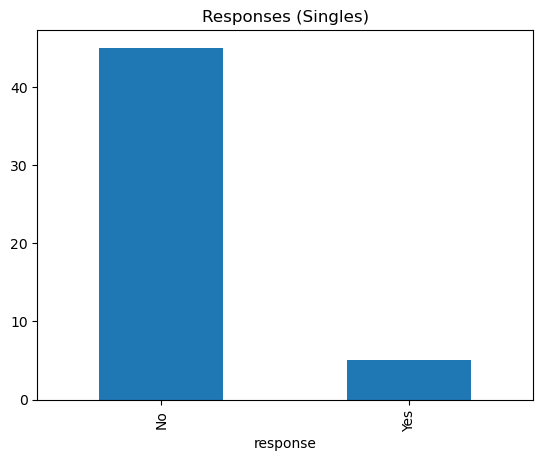

In [27]:
extract_and_analyze_results(singles, "Singles")


################# Analyzing results for Families... #################


Extraction raw result message: {'content': '{"response": "No", "justification": "Clarissa Morales-Hendrix explicitly states she would not use the WanderLux service for a vacation next year because as a single mom with two young children and limited money, she needs affordable and child-friendly trips. The luxury, child-free vacations offered by WanderLux do not fit her current life situation, preferences, or budget."}', 'refusal': None, 'role': 'assistant', 'annotations': []}


Extraction raw result message: {'content': '{"response": "No", "justification": "Calvin Hiroshi Langston Jr. prefers family-friendly vacations with young children and dislikes places that are not child-friendly. The WanderLux service focuses on quiet, adult-only luxury vacations, which does not fit his vacation preferences or current life situation."}', 'refusal': None, 'role': 'assistant', 'annotations': []}


Extraction raw result message: {'content': '{"response": "No", "justification": "Clarence Redbird Jr. explicitly states he would not use the WanderLux service because he is unemployed, has limited income and transportation, prefers simple, child-friendly, and low-cost trips close to home, and does not have the need or budget for luxury, adult-only vacations."}', 'refusal': None, 'role': 'assistant', 'annotations': []}


Extraction raw result message: {'content': '{"response": "No", "justification": "Jeremiah Lonewolf is unemployed, lives in rural Oklahoma with two young kids, and prefers simple, affordable, child-friendly vacations. The luxury, adult-only beachfront and spa destinations offered by WanderLux do not fit his needs, preferences, or budget."}', 'refusal': None, 'role': 'assistant', 'annotations': []}


Extraction raw result message: {'content': '{"response": "No", "justification": "Julian prefers family-friendly vacations that accommodate his young children and does not align with the adult-only luxury vacation service WanderLux offers. He prioritizes destinations safe and engaging for kids, which WanderLux excludes."}', 'refusal': None, 'role': 'assistant', 'annotations': []}


... (41 outputs left out)

Extraction raw result message: {'content': '{"response": "No", "justification": "Douglas Everett Whitman would not use the WanderLux service because it focuses on adult-only luxury vacations that exclude children, which conflicts with his family-oriented travel preferences. He prefers vacations that include his young children in safe, child-friendly environments and balances relaxation with educational and outdoor activities. Additionally, he is cautious about spending and looks for moderate budgets, making the luxury adult-only service unsuitable for his needs."}', 'refusal': None, 'role': 'assistant', 'annotations': []}


Extraction raw result message: {'content': '{"response": "No", "justification": "Dolores Marquez-Brown explicitly states that she would not use the WanderLux service due to her current situation caring for young grandchildren, limited finances, and preference for affordable, family-friendly vacations rather than luxury or romantic vacations without children."}', 'refusal': None, 'role': 'assistant', 'annotations': []}


Extraction raw result message: {'content': '{"response": "No", "justification": "Gordon Ellsworth Whitman has young children and prioritizes family-friendly vacations that accommodate toddlers. He prefers safe, comfortable places with activities suitable for young kids rather than quiet, adult-only luxury getaways. Financial prudence also leads him to choose practical, child-oriented vacations over luxury adult-only experiences, so he would not use the WanderLux service."}', 'refusal': None, 'role': 'assistant', 'annotations': []}


Extraction raw result message: {'content': '{"response": "No", "justification": "Caleb Hiroshi Whitman Jr. clearly states that he would not use WanderLux for his vacation next year because the service focuses on quiet, luxury, adult-only vacations which do not align with his current life situation and vacation preferences as a father of young children who prioritizes family-friendly destinations."}', 'refusal': None, 'role': 'assistant', 'annotations': []}
   response                                      justification
0        No  Clarissa Morales-Hendrix explicitly states she...
1        No  Calvin Hiroshi Langston Jr. prefers family-fri...
2        No  Clarence Redbird Jr. explicitly states he woul...
3        No  Jeremiah Lonewolf is unemployed, lives in rura...
4        No  Julian prefers family-friendly vacations that ...
5        No  Julian Everett Takahashi would not use WanderL...
6        No  Latoya Morningstar Yazzie explicitly states sh...
7        No  Isabela Marquez-Lunare

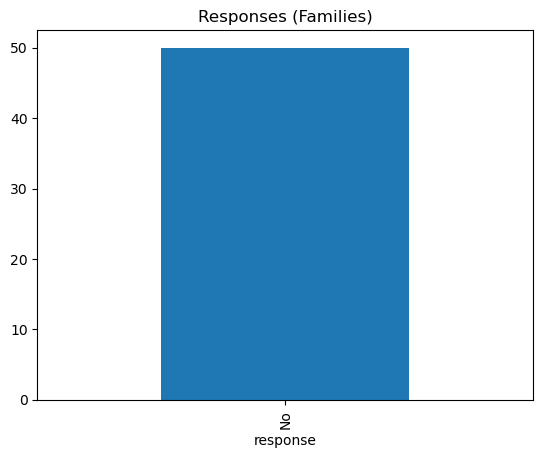

In [28]:
extract_and_analyze_results(families, "Families")

################# Analyzing results for Couples... #################


Extraction raw result message: {'content': '{"response": "No", "justification": "Kiran prefers vacations that combine active exploration and cultural immersion rather than purely quiet luxury beach resorts. Budget constraints and a preference for sustainable and meaningful travel experiences also influence the decision, making it unlikely they would use the WanderLux service for their vacation next year."}', 'refusal': None, 'role': 'assistant', 'annotations': []}


Extraction raw result message: {'content': '{"response": "Yes", "justification": "Eleanor Winthrop-Merriman stated that she would likely use the WanderLux service for her vacation next year because its focus on quiet, luxurious, and romantic beachfront and spa destinations aligns well with her preference for calm and refined travel experiences. She appreciates avoiding noisy environments and crowds, which the service promises, and considers it a suitable match for her current lifestyle and interests."}', 'refusal': None, 'role': 'assistant', 'annotations': []}


Extraction raw result message: {'content': '{"response": "Yes", "justification": "Cameron Elise Fairchild-Blythe explicitly states that she would likely use WanderLux for her vacation next year, appreciating the quiet, luxurious beach and spa getaway as a perfect way to relax and recharge. She values calm environments and wellness activities, which align well with the service offered, and also appreciates avoiding fake reviews and bad experiences."}', 'refusal': None, 'role': 'assistant', 'annotations': []}


Extraction raw result message: {'content': '{"response": "No", "justification": "Marisol prefers cultural and nature-focused vacations with her partner, usually by car, avoiding crowded or commercialized places. Although the quiet and calm aspect of the WanderLux service is appealing, she feels luxury beachfront spa vacations do not fully match her interests or budget, and she prefers more authentic, culturally rich experiences and road trips over luxury spa resorts."}', 'refusal': None, 'role': 'assistant', 'annotations': []}


Extraction raw result message: {'content': '{"response": "No", "justification": "The person explicitly states they would not use WanderLux for their vacation next year. They appreciate quiet and calm getaways but prefer authentic, nature-oriented experiences like road trips, exploring national parks, and cultural sites rather than luxury beachfront resorts. Their travel style and budget constraints do not align well with the luxury spa vacation service offered by WanderLux."}', 'refusal': None, 'role': 'assistant', 'annotations': []}


... (21 outputs left out)

Extraction raw result message: {'content': '{"response": "Yes", "justification": "Vivian states that she would likely use WanderLux for her vacation next year because it aligns with her preference for quiet, authentic, and well-curated experiences. She appreciates avoiding chaotic environments and fake reviews, and values a trusted source for luxury and calm vacations, which fits the service description."}', 'refusal': None, 'role': 'assistant', 'annotations': []}


Extraction raw result message: {'content': '{"response": "No", "justification": "Derek prefers vacations that blend cultural immersion with active experiences and some relaxation, rather than purely quiet luxury. He is cautious with finances and wants meaningful, enriching experiences, which he feels WanderLux\'s focus on quiet luxury does not fully align with."}', 'refusal': None, 'role': 'assistant', 'annotations': []}


Extraction raw result message: {'content': '{"response": "No", "justification": "Person_66_Male prefers practical, nature-oriented vacations such as road trips, fishing, and national parks over luxury beachfront or spa experiences. He is cautious about spending and feels that the WanderLux service does not fit his style or budget."}', 'refusal': None, 'role': 'assistant', 'annotations': []}


Extraction raw result message: {'content': '{"response": "Yes", "justification": "Cameron Elise Fairchild prefers quiet, classy getaways without the chaos of families with kids, values relaxation and wellness, and appreciates the promise of avoiding fake reviews and bad experiences. The WanderLux service aligns well with these preferences, making it a great fit for their vacation next year."}', 'refusal': None, 'role': 'assistant', 'annotations': []}
   response                                      justification
0        No  Kiran prefers vacations that combine active ex...
1       Yes  Eleanor Winthrop-Merriman stated that she woul...
2       Yes  Cameron Elise Fairchild-Blythe explicitly stat...
3        No  Marisol prefers cultural and nature-focused va...
4        No  The person explicitly states they would not us...
5        No  Emilio Santiago-Caldwell is a 13-year-old stud...
6        No  Rivka Tova Greenfield would not use the Wander...
7        No  Isandro prefers vacations th

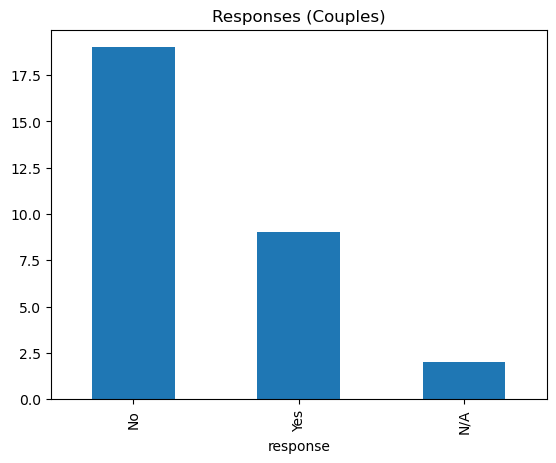

In [29]:
extract_and_analyze_results(couple, "Couples")

In [30]:
control.end()